## 01. Find and download Sentinel-1 SLC scenes

**Step 1 of 4:** **ASF search & download** → SNAP coherence processing → Python scene differencing → statistical validation

This notebook:
1. Defines the area of interest (AOI) around the Ridgecrest rupture zone.
2. Searches the Alaska Satellite Facility (ASF) archive for Sentinel-1 acquisitions.
3. Chooses a **pre-event** and a **co-event** interferometric pair, checked against the earthquake times.
4. Downloads the four SLC scenes for processing in SNAP (see [`../snap/README.md`](../snap/README.md)).

> Data volume: each IW SLC is ~4–5 GB. Downloads go to `data/raw/`, which is git-ignored.

In [ ]:
# may not need to run this - I was having environment issues with GDAL
import os, sys
from pathlib import Path

if os.name == "nt":
    env = Path(sys.prefix)
    os.environ["PATH"] = str(env / "Library" / "bin") + os.pathsep + os.environ["PATH"]
    os.environ.setdefault("GDAL_DATA", str(env / "Library" / "share" / "gdal"))
    os.environ.setdefault("PROJ_DATA", str(env / "Library" / "share" / "proj"))
    os.environ.setdefault("PROJ_LIB",  str(env / "Library" / "share" / "proj"))

In [1]:
import os, sys
from pathlib import Path
import os
from getpass import getpass
from datetime import datetime, timezone

import asf_search as asf
import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd


### Setting Repository Paths

In [3]:
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
AOI_PATH = REPO / "data" / "aoi" / "AOI_Ridgecrest_CA.kml"
RAW_DIR = REPO / "data" / "raw"
FIG_DIR = REPO / "figures"
FIG_DIR.mkdir(exist_ok=True)

## 1. Area of interest

viewing area of interest in with an interactive map. 

In [5]:
aoi = gpd.read_file(AOI_PATH)
aoi_wkt = aoi.geometry.iloc[0].wkt          # used directly as the ASF search geometry
minx, miny, maxx, maxy = aoi.total_bounds

m = folium.Map(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery",
)
folium.Rectangle([[miny, minx], [maxy, maxx]], color="cyan", weight=3,
                 fill=True, fill_opacity=0.1, popup="Ridgecrest AOI").add_to(m)
m.fit_bounds([[miny, minx], [maxy, maxx]])
m

## 2. Search the ASF archive

Constraints that matter for coherence work:

* **Product = SLC** (Single Look Complex). Coherence needs phase, which only SLCs keep.
* **Beam mode = IW**, the standard Sentinel-1 mode over land.
* **One relative orbit (track)**. Interferometric pairs must share the same viewing geometry. Ascending track **64** covers the AOI in one frame.

In [6]:
results = asf.geo_search(
    intersectsWith=aoi_wkt,
    platform=[asf.PLATFORM.SENTINEL1],
    processingLevel=asf.PRODUCT_TYPE.SLC,
    beamMode=asf.BEAMMODE.IW,
    start="2019-06-01",
    end="2019-07-31",
)

scenes = pd.DataFrame([r.properties for r in results])[
    ["sceneName", "startTime", "pathNumber", "frameNumber", "flightDirection"]
].sort_values("startTime")
print(f"{len(scenes)} SLC IW scenes found")
scenes.groupby(["pathNumber", "flightDirection"]).size()

["'type': 'EXTRA_DIMENSION': 'report': Only 2-Dimensional area of interests are supported (lon/lat), higher dimension coordinates will be ignored"]


19 SLC IW scenes found


pathNumber  flightDirection
64          ASCENDING          14
71          DESCENDING          5
dtype: int64

In [7]:
TRACK = 64
track_scenes = scenes[scenes.pathNumber == TRACK].reset_index(drop=True)
track_scenes

,sceneName,startTime,pathNumber,frameNumber,flightDirection
0,S1A_IW_SLC__1SDV_20190610T015021_20190610T0150...,2019-06-10T01:50:21Z,64,109,ASCENDING
1,S1A_IW_SLC__1SDV_20190610T015047_20190610T0151...,2019-06-10T01:50:47Z,64,114,ASCENDING
2,S1B_IW_SLC__1SDV_20190616T014958_20190616T0150...,2019-06-16T01:49:58Z,64,113,ASCENDING
3,S1A_IW_SLC__1SDV_20190622T015022_20190622T0150...,2019-06-22T01:50:22Z,64,109,ASCENDING
4,S1A_IW_SLC__1SDV_20190622T015048_20190622T0151...,2019-06-22T01:50:48Z,64,114,ASCENDING
5,S1B_IW_SLC__1SDV_20190628T014958_20190628T0150...,2019-06-28T01:49:58Z,64,113,ASCENDING
6,S1A_IW_SLC__1SDV_20190704T015023_20190704T0150...,2019-07-04T01:50:23Z,64,109,ASCENDING
7,S1A_IW_SLC__1SDV_20190704T015049_20190704T0151...,2019-07-04T01:50:49Z,64,114,ASCENDING
8,S1B_IW_SLC__1SDV_20190710T014959_20190710T0150...,2019-07-10T01:49:59Z,64,113,ASCENDING
9,S1A_IW_SLC__1SDV_20190716T015024_20190716T0150...,2019-07-16T01:50:24Z,64,109,ASCENDING


## 3. Choosing the interferometric pairs

The method compares two coherence maps with the **same temporal baseline** (12 days, the Sentinel-1A repeat):

| Pair | Purpose | Should span the earthquakes? |
|---|---|---|
| **Pre-event** | Baseline: determines baseline coherence  | No |
| **Co-event** | Includes earthquake damage: ruptured and shaken ground decorrelation | Yes |

Event times in UTC, which is the time standard of Sentinel-1 acquisitions:

* **M6.4:** 2019-07-04 17:33 UTC (10:33 PDT)
* **M7.1:** 2019-07-06 03:19 UTC (**July 5**, 20:19 PDT)

The July 4 acquisition on track 64 is at 01:50 UTC, about 16 hours before the M6.4. So the July 4 image is a pre-event image, and a June 22 → July 4 pair contains no earthquake signal. A co-event pair has to start on or before July 4 01:50 UTC and end after July 6.

In [ ]:
# Scene IDs used in this project.
PAIRS = {
    "pre": ("S1A_IW_SLC__1SDV_20190610T015047_20190610T015114_027611_031DB6_D8FA",
            "S1A_IW_SLC__1SDV_20190622T015048_20190622T015115_027786_0322F1_7A8E"),
    "co":  ("S1A_IW_SLC__1SDV_20190704T015049_20190704T015116_027961_03283A_191E",
            "S1A_IW_SLC__1SDV_20190716T015049_20190716T015116_028136_032D86_6DF2"),
}

EVENTS = {
    "M6.4": datetime(2019, 7, 4, 17, 33, 49, tzinfo=timezone.utc),
    "M7.1": datetime(2019, 7, 6, 3, 19, 53, tzinfo=timezone.utc),
}

def acq_time(scene_id: str) -> datetime:
    """Acquisition start time parsed from a Sentinel-1 scene name."""
    return datetime.strptime(scene_id.split("_")[5], "%Y%m%dT%H%M%S").replace(tzinfo=timezone.utc)

for name, (ref, sec) in PAIRS.items():
    t0, t1 = acq_time(ref), acq_time(sec)
    spans = [e for e, t in EVENTS.items() if t0 < t < t1]
    print(f"{name:>3}: {t0:%Y-%m-%d %H:%M} -> {t1:%Y-%m-%d %H:%M} UTC | "
          f"{(t1 - t0).days} days | spans: {', '.join(spans) or 'none'}")

assert not any(acq_time(PAIRS['pre'][0]) < t < acq_time(PAIRS['pre'][1]) for t in EVENTS.values()), \
    "pre-event pair must not span an earthquake"
assert all(acq_time(PAIRS['co'][0]) < t < acq_time(PAIRS['co'][1]) for t in EVENTS.values()), \
    "co-event pair must span both earthquakes"

pre: 2019-06-10 01:50 -> 2019-06-22 01:50 UTC | 12 days | spans: none
 co: 2019-07-04 01:50 -> 2019-07-16 01:50 UTC | 12 days | spans: M6.4, M7.1


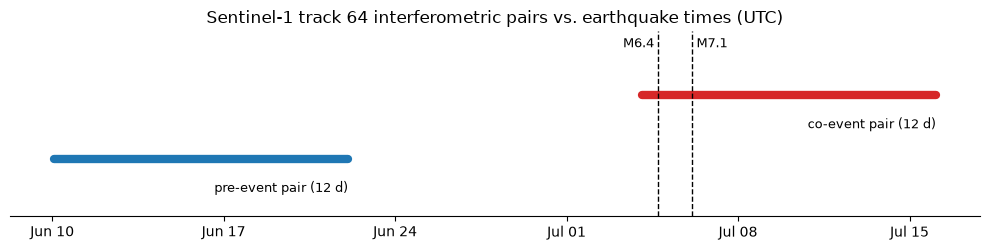

In [9]:
fig, ax = plt.subplots(figsize=(10, 2.6))
for y, (name, (ref, sec)) in enumerate(PAIRS.items()):
    t0, t1 = acq_time(ref), acq_time(sec)
    ax.plot([t0, t1], [y, y], lw=6, solid_capstyle="round",
            color="tab:blue" if name == "pre" else "tab:red")
    ax.text(t1, y - 0.35, f"{name}-event pair ({(t1 - t0).days} d)", fontsize=9, va="top", ha="right")
for (label, t), ha in zip(EVENTS.items(), ["right", "left"]):
    ax.axvline(t, color="k", ls="--", lw=1)
    ax.text(t, 1.75, f" {label} ", ha=ha, fontsize=9)
ax.set_ylim(-0.9, 2.0)
ax.set_yticks([])
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_title("Sentinel-1 track 64 interferometric pairs vs. earthquake times (UTC)")
for s in ["left", "right", "top"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "pair_timeline.png", dpi=150)
plt.show()

## 4. Download

Authentication uses a NASA Earthdata Login token (Earthdata profile → *Generate Token*).
The token is read from the `EARTHDATA_TOKEN` environment variable, or typed in when prompted. 

In [12]:
token = os.environ.get("EARTHDATA_TOKEN") or getpass("Earthdata token: ")
session = asf.ASFSession()
session.auth_with_token(token)

scene_ids = sorted({s for pair in PAIRS.values() for s in pair})
to_download = asf.product_search([f"{s}-SLC" for s in scene_ids])
print(f"{len(to_download)} of {len(scene_ids)} scenes found")

RAW_DIR.mkdir(parents=True, exist_ok=True)
missing = [r for r in to_download if not (RAW_DIR / r.properties["fileName"]).exists()]
print(f"Downloading {len(missing)} scene(s) ...")
asf.ASFSearchResults(missing).download(path=RAW_DIR, session=session, processes=2)

4 of 4 scenes found


**Next:** processing each pair in SNAP with [`snap/coherence_graph.xml`](../snap/coherence_graph.xml) (see [`snap/README.md`](../snap/README.md)), then finish with [`02_coherence_change_mapping.ipynb`](02_coherence_change_mapping.ipynb).